# 13b · Contextual enrichment without rewriting evidence

## The engineering question
Can a short model-generated prefix help retrieve a small chunk without becoming a false source fact?

**Learning outcomes:** generate real contextual prefixes at ingestion; keep generated annotations separate from canonical evidence; compare retrieval under fixed source spans; measure preprocessing cost and inspect unsupported additions.

A small chunk may omit its subject. Contextual enrichment asks a model to describe the chunk using its parent. We embed `prefix + source chunk`, but return only the original chunk as evidence. Prefixes are derived data with their own model/prompt provenance and invalidation requirements. This controlled exact-search experiment covers the six Atlas development documents and their small chunks; it does not claim a production contextual-retrieval implementation.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("13b", "G", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,query,method,source_evidence_coverage,judgment_coverage,retrieved,relevant_count,recall,mrr,ndcg,no_answer_returned_any
0,d01,source only,1.0,0.333333,3,1,1.0,1.0,1.0,None
1,d01,generated prefix + source,1.0,0.500000,2,1,1.0,1.0,1.0,None
2,d02,source only,1.0,0.500000,2,1,1.0,1.0,1.0,None
3,d02,generated prefix + source,1.0,1.000000,1,1,1.0,1.0,1.0,None
4,d03,source only,1.0,0.333333,3,1,1.0,1.0,1.0,None
5,d03,generated prefix + source,1.0,0.333333,3,1,1.0,1.0,1.0,None
6,d04,source only,1.0,0.500000,2,1,1.0,1.0,1.0,None
7,d04,generated prefix + source,1.0,1.000000,1,1,1.0,1.0,1.0,None
8,d05,source only,1.0,0.500000,2,1,1.0,1.0,1.0,None
9,d05,generated prefix + source,1.0,0.500000,2,1,1.0,1.0,1.0,None


,document,prefix,novel_words_for_review,seconds
0,atlas-warranty@1,The subject of this excerpt is the warranty pe...,"[an, excerpt, for, of, period, subject, this]",3.159784
1,atlas-warranty@1,Damage is excluded.,[],0.401178
2,atlas-reset@1,The subject is how to reset an Atlas router.,"[how, is, subject]",0.723618
3,atlas-reset@1,The subject is how to reset an Atlas router.,"[how, is, subject]",0.706620
4,atlas-reset@1,"To reset an Atlas router, hold the recessed re...",[],0.572195
5,atlas-error@1,The subject of this excerpt is the meaning and...,"[104, action, an, and, code, excerpt, for, mea...",1.520437
6,atlas-error@1,The subject of this excerpt is reconnecting th...,"[an, excerpt, issue, of, reconnecting, resolve...",0.717880
7,atlas-error@1,The subject of this excerpt is error codes rel...,"[excerpt, network, of, on, related, settings, ...",0.551124
8,atlas-firmware@1,Atlas firmware 2.0 has a specific battery requ...,"[for, has, requirement, specific, updates]",0.507384
9,atlas-firmware@1,The excerpt discusses keeping external power c...,"[devices, discusses, excerpt, for, keeping, the]",0.514759


atlas-warranty@1 The subject of this excerpt is the warranty period for an Atlas router.
atlas-warranty@1 Damage is excluded.
atlas-reset@1 The subject is how to reset an Atlas router.
atlas-reset@1 The subject is how to reset an Atlas router.
atlas-reset@1 To reset an Atlas router, hold the recessed reset button for ten seconds.
atlas-error@1 The subject of this excerpt is the meaning and action required for an Atlas error code 104 related to a disconnected WAN cable.
atlas-error@1 The subject of this excerpt is reconnecting the WAN cable to resolve an issue with the router's configuration.
atlas-error@1 The subject of this excerpt is error codes related to network settings on a router.
atlas-firmware@1 Atlas firmware 2.0 has a specific battery requirement for updates.
atlas-firmware@1 The excerpt discusses keeping external power connected during firmware installation for Atlas devices.
atlas-firmware@1 The subject of this excerpt is the requirement for a minimum battery percentage in

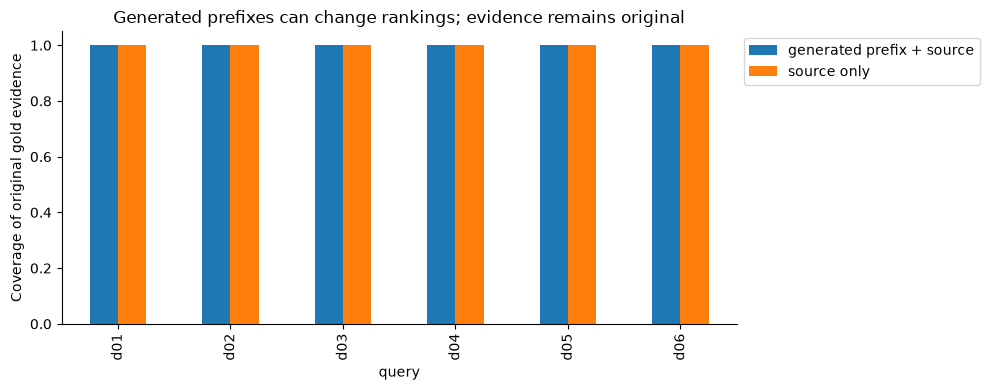

In [2]:
import re
from vector_masterclass.data import documents, queries
from vector_masterclass.chunking import chunk_document
from vector_masterclass.models import embed, generate, release_models
from vector_masterclass.retrieval import exact_search, tokenize
from vector_masterclass.metrics import evidence_coverage, ranking_metrics
from vector_masterclass.context import validate_chunk
from vector_masterclass.evidence import json_write

docs = [d for d in documents(tenant="public") if d.family == "atlas"]
sources = {d.key: d for d in docs}
chunks = [c for d in docs for c in chunk_document(d, words=16, overlap=4)]
traces = []
for chunk in chunks:
    doc = sources[chunk.document_key]
    result = generate(
        f"Using only the parent text, write one short sentence identifying the subject of this excerpt. Do not add facts. Output only the sentence.\nParent: {doc.text}\nExcerpt: {chunk.text}",
        max_new_tokens=64,
    )
    novel = sorted(set(tokenize(result["text"])) - set(tokenize(doc.text)))
    traces.append(
        {
            "chunk_id": chunk.id,
            "document_key": chunk.document_key,
            "source_hash": chunk.source_hash,
            "prefix": result["text"],
            "novel_words_for_review": novel,
            "generation": result,
        }
    )
    validate_chunk(chunk, docs, "public")
json_write(lesson.path / "enrichment-traces.json", traces)
release_models()
ids = [c.id for c in chunks]
lookup = {c.id: c for c in chunks}
representations = {
    "source only": embed([c.text for c in chunks]),
    "generated prefix + source": embed(
        [t["prefix"] + " " + c.text for t, c in zip(traces, chunks)]
    ),
}
rows = []
for q in queries("development"):
    vector = embed([q.text], role="query")[0]
    for method, matrix in representations.items():
        ranked = exact_search(vector, matrix, ids, k=3)
        selected = [lookup[id_] for id_, s in ranked]
        rows.append(
            {
                "query": q.id,
                "method": method,
                "source_evidence_coverage": evidence_coverage(selected, q.evidence)["coverage"],
                **ranking_metrics([c.document_key for c in selected], q.relevance, k=3),
            }
        )
results = lesson.table(pd.DataFrame(rows))
display(results)
display(
    lesson.table(
        pd.DataFrame(
            [
                {
                    "document": t["document_key"],
                    "prefix": t["prefix"],
                    "novel_words_for_review": t["novel_words_for_review"],
                    "seconds": t["generation"]["seconds"],
                }
                for t in traces
            ]
        ),
        "prefixes",
    )
)
for trace in traces:
    print(trace["document_key"], trace["prefix"])
fig, ax = plt.subplots(figsize=(10, 4))
results.dropna(subset=["source_evidence_coverage"]).pivot(
    index="query", columns="method", values="source_evidence_coverage"
).plot.bar(ax=ax)
ax.set(
    ylabel="Coverage of original gold evidence",
    ylim=(0, 1.05),
    title="Generated prefixes can change rankings; evidence remains original",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Novel words are review flags, not an entailment test: a faithful paraphrase can use new words and a false claim can reuse source words. Inspect prefixes against their parents, especially numbers and product identities. A contextual prefix can make several chunks almost identical and reduce discrimination. Compare source-evidence coverage, not similarity to the generated text.

The reference run achieved equal coverage with both representations in this restricted six-document corpus. One prefix reduced “accidental water damage” to “damage,” losing a qualification; another changed E104 to 104. Neither problem was detected by the aggregate retrieval score. No-answer questions have undefined evidence coverage and are omitted from the plot.

**Exercise:** remove the product name from an excerpt but retain it in the parent. Determine whether enrichment helps. Then inject an unsupported number into a prefix and explain why the original source-span validation still passes—the vector representation changed, but the source text did not. Add a separate annotation-quality check rather than claiming provenance prevents all poisoning.

Preprocessing cost is paid per chunk and again after relevant source/model/prompt changes. Query-time savings must be balanced against ingestion latency, storage of annotations, invalidation, and possible retrieval drift. This notebook holds the encoder and top-k fixed and labels the generated text as derived data throughout.

In [3]:
manifest = lesson.finish(
    {
        "every_prefix_live": len(traces) == len(chunks)
        and all(t["generation"]["live"] for t in traces),
        "source_hashes_unchanged": all(
            c.source_hash == sources[c.document_key].sha256 for c in chunks
        ),
        "both_representations_evaluated": results.method.nunique() == 2,
        "no_generated_text_in_source": all(
            c.text == sources[c.document_key].text[c.start : c.end] for c in chunks
        ),
    },
    observations={
        "ingestion_generation_calls": len(traces),
        "ingestion_generation_seconds": sum(t["generation"]["seconds"] for t in traces),
        "query_generation_calls": 0,
        "novel_word_flags_are_not_entailment": True,
    },
)

{
  "artifact": "artifacts/20261031T053510Z-6b686e/13b",
  "checks": {
    "every_prefix_live": true,
    "source_hashes_unchanged": true,
    "both_representations_evaluated": true,
    "no_generated_text_in_source": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.